# 03 · Is the hotspot statistically significant?

A density map shows where crime is concentrated, but not whether that concentration could have happened by chance. **Getis-Ord Gi\*** tests each area: is it surrounded by neighbours with unusually high (hot spot) or low (cold spot) values?

| Step | What happens |
|---|---|
| 1 | Count incidents and venues in each of Leeds's 488 LSOAs |
| 2 | Run Getis-Ord Gi\* on incident counts |
| 3 | Map the hot and cold spots |
| 4 | Test whether LSOAs with more venues have more crime |

In [1]:
import sys
from pathlib import Path

# Make the project's `src` package importable from inside notebooks/
sys.path.insert(0, str(Path.cwd().resolve().parent))

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch
from scipy.stats import spearmanr

from src import config, geo, plotting, stats

## Step 1 · Counts per LSOA

In [2]:
crimes = pd.read_csv(config.CRIMES_CLEAN)
venues = pd.read_csv(config.VENUES_CLEAN)
lsoas = geo.load_leeds_lsoas()

crime_pts = geo.to_points(crimes, lon="Longitude", lat="Latitude")
venue_pts = geo.to_points(venues, lon="longitude", lat="latitude")

areas = stats.count_points_per_area(lsoas, crime_pts, "incidents")
areas = stats.count_points_per_area(areas, venue_pts, "venues")
print(f"Incidents assigned to an LSOA: {areas['incidents'].sum():,} of {len(crime_pts):,}")
print(f"Venues assigned to an LSOA:    {areas['venues'].sum():,} of {len(venue_pts):,}")

Leeds LSOAs: 488 (of 35,672 in England and Wales)


Incidents assigned to an LSOA: 111,549 of 111,549
Venues assigned to an LSOA:    714 of 715


As a cross-check, the police data also records each incident's LSOA code. Most incidents should fall inside the polygon their code names:

In [3]:
joined = gpd.sjoin(crime_pts, lsoas[["LSOA21CD", "geometry"]], predicate="within")
agree = (joined["LSOA code"] == joined["LSOA21CD"]).mean()
print(f"Incidents inside the LSOA their police code names: {agree:.1%}")
areas["incidents"].describe().round(1).to_frame("incidents per LSOA")

Incidents inside the LSOA their police code names: 95.9%


,incidents per LSOA
count,488.0
mean,228.6
std,321.7
min,19.0
25%,93.0
50%,173.0
75%,307.0
max,6143.0


The remaining incidents sit just across a boundary from their recorded LSOA, because the police move each location to an anonymous map point. A few also carry older 2011 LSOA codes. Counting by polygon keeps every incident consistent with the 2021 boundaries used for the maps and the Gi\\* test.

## Step 2 · Getis-Ord Gi\*

* **Neighbours:** Queen contiguity, so LSOAs that share any edge or corner are neighbours.
* **Gi\* score:** compares the total of an LSOA *plus its neighbours* with the Leeds-wide average. A high positive score means a cluster of high values.
* **Significance:** 9,999 random permutations of the counts give a pseudo p-value for each LSOA, and LSOAs are classed at 90/95/99% confidence.
* **Multiple testing:** testing 488 areas at once produces some false positives, so a false discovery rate (FDR) correction is also reported.

In [4]:
areas = stats.getis_ord_gi_star(areas, "incidents")
gi_summary = stats.summarise_gi(areas)
gi_summary.to_csv(config.TABLES_DIR / "gi_star_summary.csv", index=False)

hot = areas["gi_class"].str.startswith("Hot spot") & (areas["gi_p"] <= config.GI_ALPHA)
print(f"Hot-spot LSOAs at 95%+: {hot.sum()}  |  still significant after FDR: {(hot & areas['gi_fdr_sig']).sum()}")
gi_summary

Hot-spot LSOAs at 95%+: 65  |  still significant after FDR: 6


,Gi* class,LSOAs
0,"Hot spot, 99% confidence",8
1,"Hot spot, 95% confidence",57
2,"Hot spot, 90% confidence",45
3,Not significant,260
4,"Cold spot, 90% confidence",44
5,"Cold spot, 95% confidence",42
6,"Cold spot, 99% confidence",32


The LSOAs with the strongest hot-spot scores:

In [5]:
top_hot = (areas.sort_values("gi_z", ascending=False)
           [["LSOA21NM", "incidents", "venues", "gi_z", "gi_p", "gi_fdr_sig"]].head(10)
           .rename(columns={"LSOA21NM": "LSOA", "gi_z": "Gi* z", "gi_p": "p (pseudo)", "gi_fdr_sig": "Significant after FDR"}))
top_hot.to_csv(config.TABLES_DIR / "gi_star_top_hotspots.csv", index=False)
top_hot.round({"Gi* z": 2, "p (pseudo)": 4})

,LSOA,incidents,venues,Gi* z,p (pseudo),Significant after FDR
463,Leeds 111B,6143,96,4.47,0.0001,True
462,Leeds 111A,1093,18,3.99,0.0004,True
467,Leeds 111E,1097,35,3.35,0.0001,True
460,Leeds 055F,477,2,3.34,0.0019,False
464,Leeds 111C,2132,26,3.03,0.0004,True
476,Leeds 055J,231,1,2.90,0.0003,True
469,Leeds 064E,485,1,2.43,0.0001,True
487,Leeds 112F,260,5,1.53,0.0127,False
470,Leeds 075F,89,1,1.36,0.0083,False
69,Leeds 064A,174,1,1.29,0.0112,False


## Step 3 · Map the hot and cold spots

Saved results\figures\getis_ord_hotspots.png


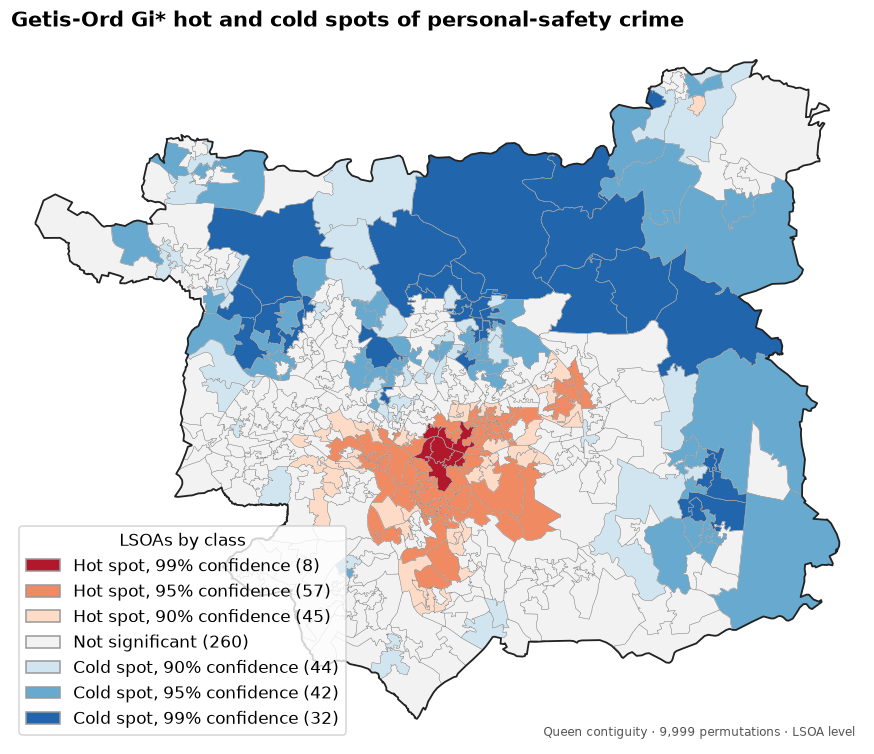

In [6]:
colours = dict(stats.GI_CLASSES)
counts = areas["gi_class"].value_counts()

fig, ax = plotting.map_axes(lsoas, "Getis-Ord Gi* hot and cold spots of personal-safety crime", basemap=False)
areas.plot(ax=ax, color=areas["gi_class"].map(colours), edgecolor="white", linewidth=0.3, zorder=2)
plotting.draw_lsoas(ax, lsoas)
handles = [Patch(facecolor=c, edgecolor="#999", label=f"{label} ({counts.get(label, 0)})")
           for label, c in stats.GI_CLASSES]
ax.legend(handles=handles, loc="lower left", title="LSOAs by class", frameon=True)
ax.annotate("Queen contiguity · 9,999 permutations · LSOA level", xy=(0.99, 0.01),
            xycoords="axes fraction", ha="right", fontsize=8, color="#555")
plotting.save(fig, "getis_ord_hotspots");

## Step 4 · Do LSOAs with more venues have more crime?

The maps compare locations. This step tests the association directly across all 488 LSOAs. Spearman's rank correlation is used because both counts are heavily skewed: a few LSOAs have very high values.

In [7]:
rho, p = spearmanr(areas["venues"], areas["incidents"])
print(f"Spearman correlation between venues and incidents per LSOA: rho = {rho:.2f} (p = {p:.1e})")

by_venues = (areas.assign(group=pd.cut(areas["venues"], [-1, 0, 2, 5, 1000], labels=["0", "1–2", "3–5", "6+"]))
             .groupby("group", observed=True)
             .agg(LSOAs=("incidents", "size"), median_incidents=("incidents", "median"), mean_incidents=("incidents", "mean"))
             .round(0))
by_venues.to_csv(config.TABLES_DIR / "incidents_by_venue_count.csv")
by_venues

Spearman correlation between venues and incidents per LSOA: rho = 0.15 (p = 9.0e-04)


,LSOAs,median_incidents,mean_incidents
group,,,
0,228,166.0,196.0
1–2,202,150.0,206.0
3–5,40,224.0,276.0
6+,18,286.0,792.0


In [8]:
hot95 = areas["gi_class"].isin(["Hot spot, 99% confidence", "Hot spot, 95% confidence"])
share = pd.DataFrame({
    "Share of Leeds area (%)": [100 * areas.loc[hot95].area.sum() / areas.area.sum()],
    "Share of incidents (%)": [100 * areas.loc[hot95, "incidents"].sum() / areas["incidents"].sum()],
    "Share of venues (%)": [100 * areas.loc[hot95, "venues"].sum() / areas["venues"].sum()],
}, index=["Hot-spot LSOAs (95%+)"]).round(1)
share.to_csv(config.TABLES_DIR / "hotspot_concentration.csv")
share

,Share of Leeds area (%),Share of incidents (%),Share of venues (%)
Hot-spot LSOAs (95%+),6.1,30.3,34.0


In [9]:
areas.to_crs(config.CRS_WGS84).to_file(config.LSOA_STATS, driver="GeoJSON")
print("Saved", config.LSOA_STATS.relative_to(config.PROJECT_ROOT))

Saved data\processed\leeds_lsoa_stats.geojson


**Summary:** the city-centre cluster is a statistically significant hot spot, and it holds a far larger share of both incidents and venues than its share of the land area. Across all LSOAs, more venues goes with more crime. Next: [04_temporal_patterns.ipynb](04_temporal_patterns.ipynb).